# Applying Synthetic-Optimized Parameters to NGRIP (Notebook 2 of 2)

**Goal:** take the `KS_test`/`ruptures` parameters found in `Parameter_Optimization_Synthetic.ipynb`
(optimized against synthetic Melcher25 data via leakage-free K-fold CV) and apply them, unchanged,
to the real NGRIP $\delta^{18}$O record — then compare against the literature-default parameters
already validated in `KS_test_Validation.ipynb` / `Ruptures_Validation.ipynb`.

**Evaluation convention differs deliberately from notebook 1:** the synthetic optimization scored
detections against *all* known transitions (both directions, since the Melcher25 system is
bistable and switches both ways). Here, matching `KS_test_Validation.ipynb`/`Ruptures_Validation.ipynb`,
only **upward** (warming) detections are scored, against the 25 main Dansgaard-Oeschger onset
times from Rasmussen et al. (2014) -- that catalog only lists warming events, so downward
detections have no ground truth to be scored against here.

**Literature baselines for comparison** (already established in the Ammonyte repo):
- `KS_test` (Bagniewski et al. 2021 params): F1 = 0.51 (19/25 events, 76% recall, 39% precision)
- `ruptures` (`Pelt`, `l2` cost, `pen=10`): F1 = 0.42 (14/25 events, 56% recall, 34% precision)


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ammonyte as amt

AMMONYTE_DATA_DIR = "/Users/maryamniati/Documents/Ammonyte/Ammonyte/ammonyte/data"
SYNTHETIC_DIR = "/Users/maryamniati/Documents/Syntheticdata"
TOLERANCE = 0.5  # kyr -- matches KS_test_Validation.ipynb / Ruptures_Validation.ipynb


---
## Section 1 — Load NGRIP + Known DO Events

Same loading pattern as `KS_test_Validation.ipynb` / `Ruptures_Validation.ipynb`, so results are
directly comparable.


Time axis values sorted in ascending order
Time axis values sorted in ascending order
NGRIP: 6112 points, 0.05-122.27 kyr b2k
Main DO warming events: 25


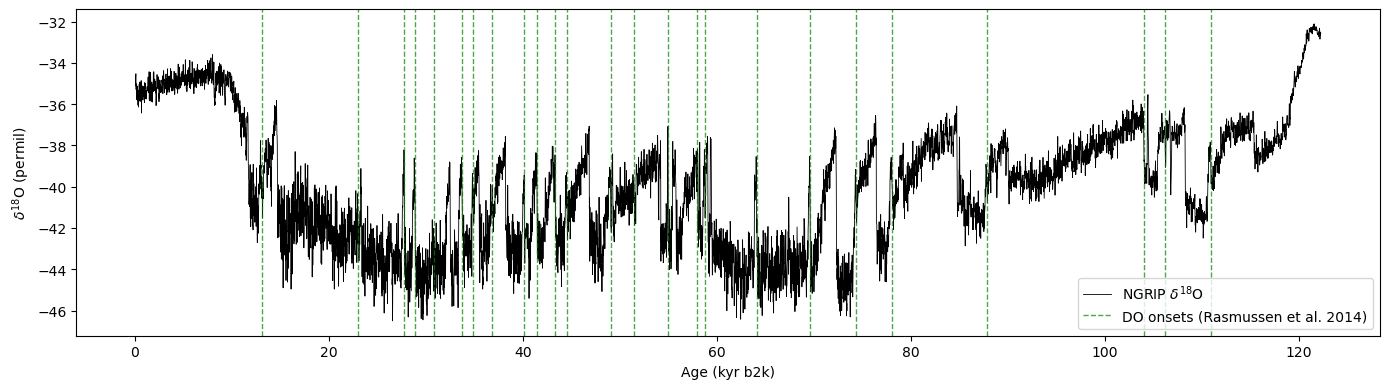

In [2]:
ngrip = amt.Series.from_csv(f"{AMMONYTE_DATA_DIR}/NGRIP.csv")
do_events = pd.read_csv(f"{AMMONYTE_DATA_DIR}/DO_events.csv", comment='#')
main_do_events = do_events['main_kyr_b2k'].dropna().values

print(f"NGRIP: {len(ngrip.time)} points, {ngrip.time.min():.2f}-{ngrip.time.max():.2f} {ngrip.time_unit}")
print(f"Main DO warming events: {len(main_do_events)}")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='black', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='--', lw=1.0, alpha=0.7, label='DO onsets (Rasmussen et al. 2014)' if i == 0 else None)
ax.set_xlabel('Age (kyr b2k)'); ax.set_ylabel('$\\delta^{18}$O (permil)')
ax.legend(); plt.tight_layout(); plt.show()


---
## Section 2 — Load the Optimized Parameters

From `Parameter_Optimization_Synthetic.ipynb`'s `optimized_parameters.json` -- the CV `f1_score`
recorded here is the synthetic-data estimate, kept alongside the NGRIP score below for direct
comparison (that gap *is* the result of this notebook).


In [3]:
with open(f"{SYNTHETIC_DIR}/optimized_parameters.json") as f:
    optimized = json.load(f)

print(f"Synthetic source: {optimized['synthetic_source']}")
for name, info in optimized['methods'].items():
    print(f"  {name}: synthetic CV F1 = {info['score']['f1_score']:.3f} +/- {info['score']['f1_std']:.3f}  params={info['params']}")


Synthetic source: best_config.json (Melcher25, sigma=0.371, gamma=1.458, alpha=-0.450, sigma_noise=0.046)
  KS_test: synthetic CV F1 = 0.678 +/- 0.002  params={'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184}
  ruptures_Binseg_l2: synthetic CV F1 = 0.929 +/- 0.016  params={'algo': 'Binseg', 'cost': 'l2', 'pen': 4.996078250812123, 'min_size': 7, 'jump': 1}
  ruptures_Window_l2: synthetic CV F1 = 0.283 +/- 0.025  params={'algo': 'Window', 'cost': 'l2', 'pen': 2.2977428962946447, 'min_size': 14, 'jump': 1, 'width': 207}


---
## Section 3 — `KS_test`: Optimized vs. Literature Parameters on NGRIP

Both configurations run on the same NGRIP series; only upward detections are scored against
`main_do_events` (see the convention note above).


In [4]:
ks_optimized_params = optimized['methods']['KS_test']['params']
ks_literature_params = dict(w_min=0.12, w_max=2.5, n_w=15, d_c=0.77, n_c=3, s_c=2.0, x_c=0.8)

def evaluate_kstest(params, label):
    transitions = ngrip.kstest(**params)
    upward_mask = transitions.jump_values == 1
    detected_upward = transitions.jump_times[upward_mask]
    detected_upward = detected_upward[~np.isnan(detected_upward)]
    m = amt.utils.evaluate_detection(detected_upward, main_do_events, tolerance=TOLERANCE)
    print(f"{label}: F1={m.f1_score:.3f}  precision={m.precision:.3f}  recall={m.recall:.3f}  "
          f"({m.true_positives}/{m.n_ground_truth} events, {m.n_detected} detected)")
    return transitions, detected_upward, m

ks_opt_transitions, ks_opt_detected, ks_opt_metrics = evaluate_kstest(
    {**ks_optimized_params, 'x_c': None}, "KS_test (synthetic-optimized)")
ks_lit_transitions, ks_lit_detected, ks_lit_metrics = evaluate_kstest(
    ks_literature_params, "KS_test (literature, Bagniewski et al. 2021)")


KS_test (synthetic-optimized): F1=0.053  precision=0.077  recall=0.040  (1/25 events, 13 detected)
KS_test (literature, Bagniewski et al. 2021): F1=0.514  precision=0.388  recall=0.760  (19/25 events, 49 detected)


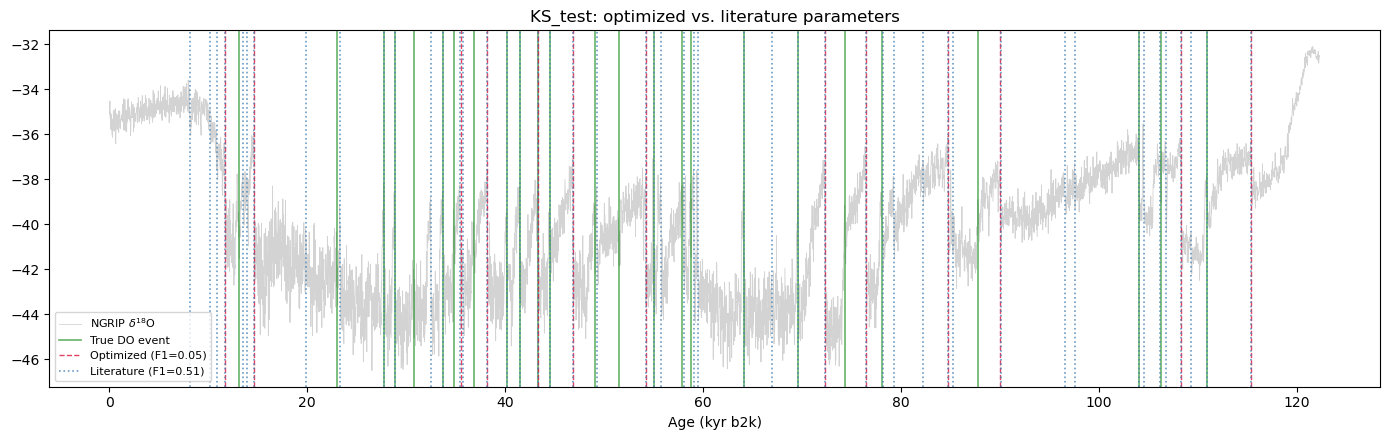

In [5]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='lightgray', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)
for i, t in enumerate(ks_opt_detected):
    ax.axvline(t, color='crimson', ls='--', lw=1.0, alpha=0.8,
               label=f'Optimized (F1={ks_opt_metrics.f1_score:.2f})' if i == 0 else None)
for i, t in enumerate(ks_lit_detected):
    ax.axvline(t, color='steelblue', ls=':', lw=1.2, alpha=0.8,
               label=f'Literature (F1={ks_lit_metrics.f1_score:.2f})' if i == 0 else None)
ax.set_xlabel('Age (kyr b2k)'); ax.set_title('KS_test: optimized vs. literature parameters')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


---
## Section 4 — `ruptures`: Optimized vs. Literature Parameters on NGRIP


In [6]:
rupt_optimized_params = optimized['methods']['ruptures_Binseg_l2']['params']
rupt_literature_params = dict(algo='Pelt', cost='l2', pen=10)

def evaluate_ruptures(params, label):
    transitions = ngrip.ruptures(**params)
    upward_mask = transitions.jump_values == 1
    detected_upward = transitions.jump_times[upward_mask]
    detected_upward = detected_upward[~np.isnan(detected_upward)]
    m = amt.utils.evaluate_detection(detected_upward, main_do_events, tolerance=TOLERANCE)
    print(f"{label}: F1={m.f1_score:.3f}  precision={m.precision:.3f}  recall={m.recall:.3f}  "
          f"({m.true_positives}/{m.n_ground_truth} events, {m.n_detected} detected)")
    return transitions, detected_upward, m

rupt_opt_transitions, rupt_opt_detected, rupt_opt_metrics = evaluate_ruptures(
    rupt_optimized_params, "ruptures (synthetic-optimized, Binseg/l2)")
rupt_lit_transitions, rupt_lit_detected, rupt_lit_metrics = evaluate_ruptures(
    rupt_literature_params, "ruptures (baseline, Pelt/l2/pen=10)")


ruptures (synthetic-optimized, Binseg/l2): F1=0.434  precision=0.310  recall=0.720  (18/25 events, 58 detected)
ruptures (baseline, Pelt/l2/pen=10): F1=0.424  precision=0.341  recall=0.560  (14/25 events, 41 detected)


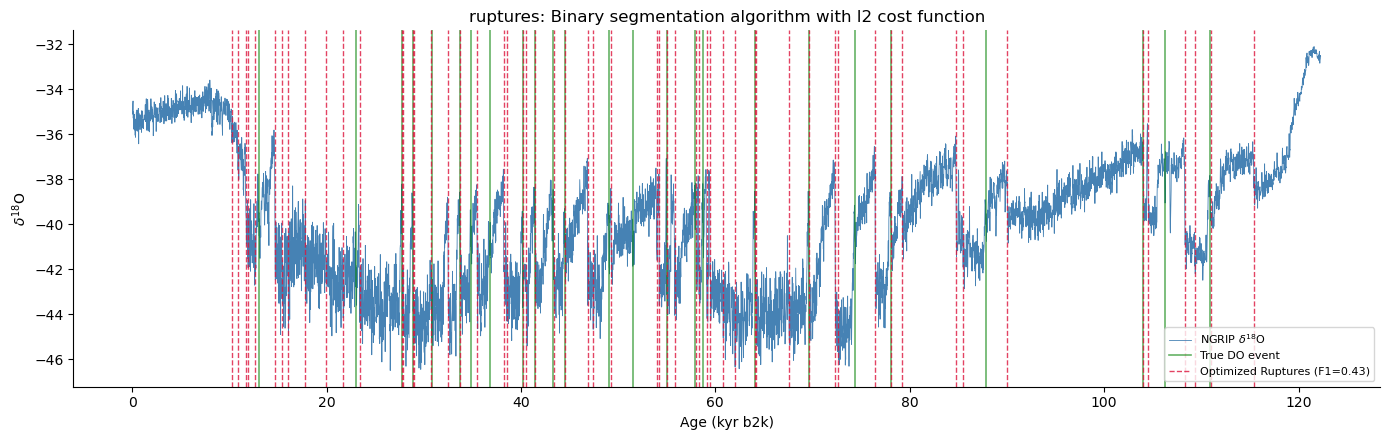

In [7]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='steelblue', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)
for i, t in enumerate(rupt_opt_detected):
    ax.axvline(t, color='crimson', ls='--', lw=1.0, alpha=0.8,
               label=f'Optimized Ruptures (F1={rupt_opt_metrics.f1_score:.2f})' if i == 0 else None)
# for i, t in enumerate(rupt_lit_detected):
#     ax.axvline(t, color='steelblue', ls=':', lw=1.2, alpha=0.8,
#                label=f'Baseline (F1={rupt_lit_metrics.f1_score:.2f})' if i == 0 else None)
ax.set_xlabel('Age (kyr b2k)'); ax.set_ylabel('$\\delta^{18}$O'); ax.set_title('ruptures: Binary segmentation algorithm with l2 cost function')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


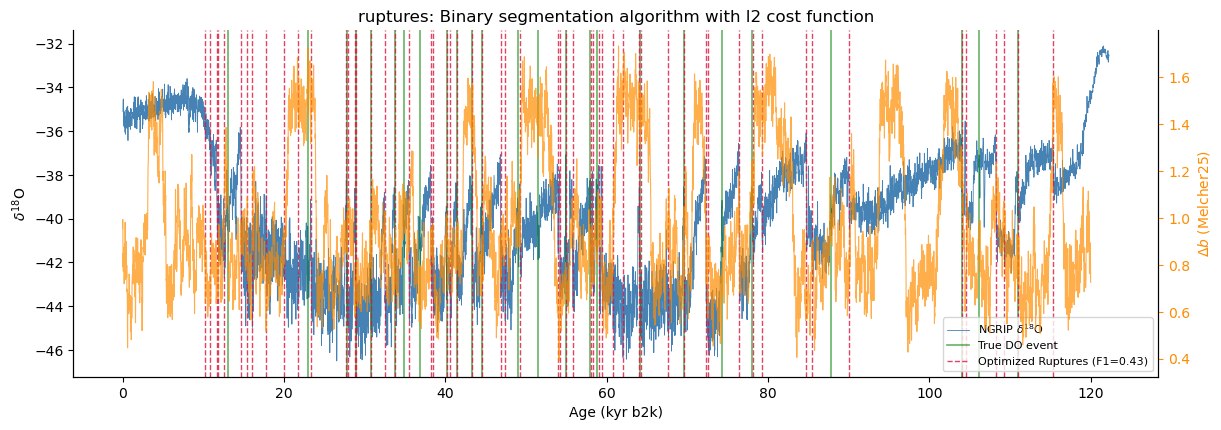

In [16]:
melcher = pd.read_csv(f"{SYNTHETIC_DIR}/example_synthetic_dataset.csv")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='steelblue', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)
for i, t in enumerate(rupt_opt_detected):
    ax.axvline(t, color='crimson', ls='--', lw=1.0, alpha=0.8,
               label=f'Optimized Ruptures (F1={rupt_opt_metrics.f1_score:.2f})' if i == 0 else None)

ax2 = ax.twinx()
ax2.plot(melcher['time'], melcher['db_noisy'], lw=0.8, color='darkorange', alpha=0.7,
         label='Melcher25 synthetic $\\Delta b$')
ax2.set_ylabel('$\\Delta b$ (Melcher25)', color='darkorange')
ax2.tick_params(axis='y', colors='darkorange')

ax.set_xlabel('Age (kyr b2k)'); ax.set_ylabel('$\\delta^{18}$O')
ax.set_title('ruptures: Binary segmentation algorithm with l2 cost function')
ax.legend(fontsize=8)
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)


Melcher25 (optimized ruptures): F1=0.947  precision=1.000  recall=0.900


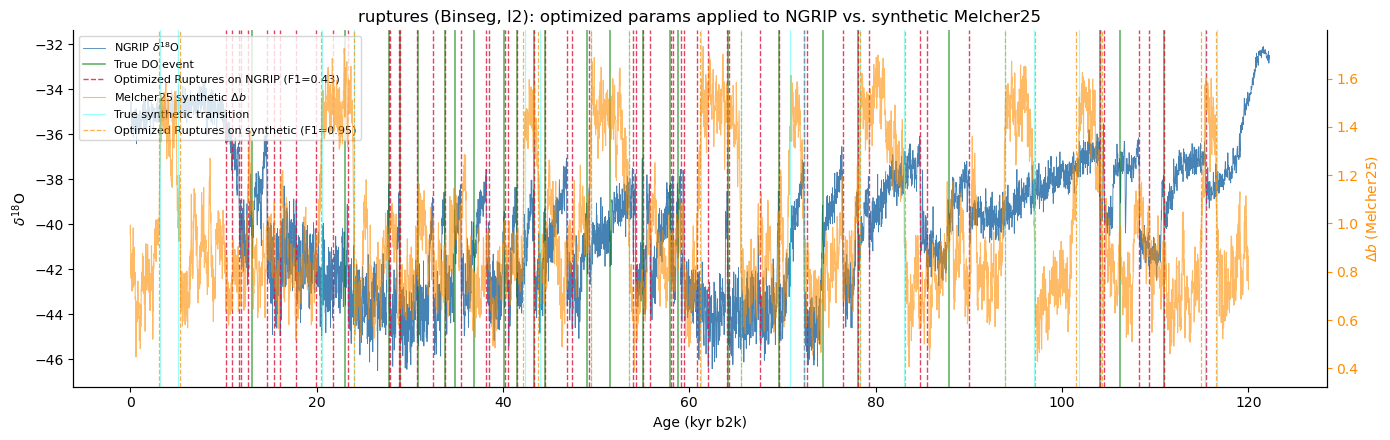

In [28]:
melcher_series = amt.Series(time=melcher['time'].values, value=melcher['db_noisy'].values,
                             label='Melcher25_synthetic', verbose=False)

melcher_opt_transitions = melcher_series.ruptures(**rupt_optimized_params)
melcher_opt_detected = melcher_opt_transitions.jump_times[~np.isnan(melcher_opt_transitions.jump_times)]

melcher_true_states = melcher['state_true'].values
melcher_true_idx = np.where(np.diff(melcher_true_states) != 0)[0] + 1
melcher_true_transitions = melcher['time'].values[melcher_true_idx]

melcher_opt_metrics = amt.utils.evaluate_detection(melcher_opt_detected, melcher_true_transitions, tolerance=TOLERANCE)
print(f"Melcher25 (optimized ruptures): F1={melcher_opt_metrics.f1_score:.3f}  "
      f"precision={melcher_opt_metrics.precision:.3f}  recall={melcher_opt_metrics.recall:.3f}")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='steelblue', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)
for i, t in enumerate(rupt_opt_detected):
    ax.axvline(t, color='crimson', ls='--', lw=1.0, alpha=0.8,
               label=f'Optimized Ruptures on NGRIP (F1={rupt_opt_metrics.f1_score:.2f})' if i == 0 else None)

ax2 = ax.twinx()
ax2.plot(melcher['time'], melcher['db_noisy'], lw=0.8, color='darkorange', alpha=0.6,
         label='Melcher25 synthetic $\\Delta b$')
for i, t in enumerate(melcher_true_transitions):
    ax2.axvline(t, color='cyan', ls='-', lw=0.9, alpha=0.4,
                label='True synthetic transition' if i == 0 else None)
for i, t in enumerate(melcher_opt_detected):
    ax2.axvline(t, color='darkorange', ls='--', lw=0.9, alpha=0.7,
                label=f'Optimized Ruptures on synthetic (F1={melcher_opt_metrics.f1_score:.2f})' if i == 0 else None)
ax2.set_ylabel('$\\Delta b$ (Melcher25)', color='darkorange')
ax2.tick_params(axis='y', colors='darkorange')

ax.set_xlabel('Age (kyr b2k)'); ax.set_ylabel('$\\delta^{18}$O')
ax.set_title('ruptures (Binseg, l2): optimized params applied to NGRIP vs. synthetic Melcher25')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

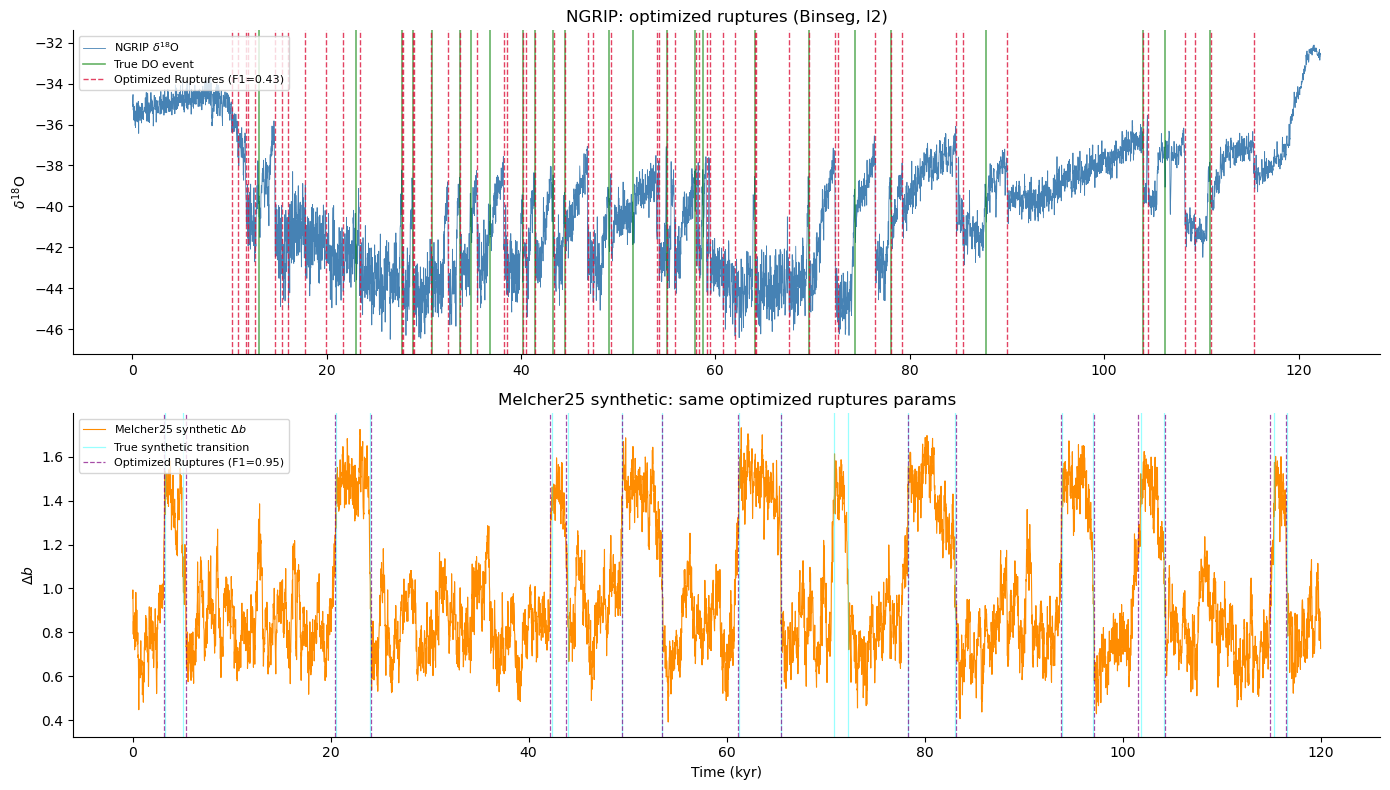

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

# --- Top: NGRIP ---
ax1.plot(ngrip.time, ngrip.value, lw=0.6, color='steelblue', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax1.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)
for i, t in enumerate(rupt_opt_detected):
    ax1.axvline(t, color='crimson', ls='--', lw=1.0, alpha=0.8,
                label=f'Optimized Ruptures (F1={rupt_opt_metrics.f1_score:.2f})' if i == 0 else None)
ax1.set_ylabel('$\\delta^{18}$O')
ax1.set_title('NGRIP: optimized ruptures (Binseg, l2)')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(fontsize=8, loc='upper left')

# --- Bottom: Melcher25 synthetic ---
ax2.plot(melcher['time'], melcher['db_noisy'], lw=0.8, color='darkorange', label='Melcher25 synthetic $\\Delta b$')
for i, t in enumerate(melcher_true_transitions):
    ax2.axvline(t, color='cyan', ls='-', lw=0.9, alpha=0.4, label='True synthetic transition' if i == 0 else None)
for i, t in enumerate(melcher_opt_detected):
    ax2.axvline(t, color='purple', ls='--', lw=0.9, alpha=0.7,
                label=f'Optimized Ruptures (F1={melcher_opt_metrics.f1_score:.2f})' if i == 0 else None)
ax2.set_xlabel('Time (kyr)')
ax2.set_ylabel('$\\Delta b$')
ax2.set_title('Melcher25 synthetic: same optimized ruptures params')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.show()

---
## Section 5 — Summary: Synthetic CV Estimate vs. Actual NGRIP Performance

The gap between columns 1 and 2 below is the actual result of this two-notebook pipeline --
it's the honest answer to "does synthetic-data optimization transfer to real NGRIP," per
method.


In [8]:
summary = pd.DataFrame([
     
    dict(method='KS_test', variant='synthetic-optimized',
         synthetic_cv_f1=optimized['methods']['KS_test']['score']['f1_score'],
         ngrip_f1=ks_opt_metrics.f1_score, ngrip_precision=ks_opt_metrics.precision, ngrip_recall=ks_opt_metrics.recall),
    dict(method='KS_test', variant='literature',
         synthetic_cv_f1=np.nan,
         ngrip_f1=ks_lit_metrics.f1_score, ngrip_precision=ks_lit_metrics.precision, ngrip_recall=ks_lit_metrics.recall),
    dict(method='ruptures_Binseg_l2', variant='synthetic-optimized',
         synthetic_cv_f1=optimized['methods']['ruptures_Binseg_l2']['score']['f1_score'],
         ngrip_f1=rupt_opt_metrics.f1_score, ngrip_precision=rupt_opt_metrics.precision, ngrip_recall=rupt_opt_metrics.recall),
    dict(method='ruptures_Pelt_l2', variant='baseline (pen=10)',
         synthetic_cv_f1=np.nan,
         ngrip_f1=rupt_lit_metrics.f1_score, ngrip_precision=rupt_lit_metrics.precision, ngrip_recall=rupt_lit_metrics.recall),
])
# summary.to_csv(f"{SYNTHETIC_DIR}/ngrip_comparison_summary.csv", index=False)
print(f"Saved {SYNTHETIC_DIR}/ngrip_comparison_summary.csv")
summary


Saved /Users/maryamniati/Documents/Syntheticdata/ngrip_comparison_summary.csv


,method,variant,synthetic_cv_f1,ngrip_f1,ngrip_precision,ngrip_recall
0,KS_test,synthetic-optimized,0.677855,0.052632,0.076923,0.04
1,KS_test,literature,NaN,0.513514,0.387755,0.76
2,ruptures_Binseg_l2,synthetic-optimized,0.929156,0.433735,0.310345,0.72
3,ruptures_Pelt_l2,baseline (pen=10),NaN,0.424242,0.341463,0.56


---
## Section 6 — Noise-Grid Transfer: Optimized parameters (white/pink/red) on NGRIP

Sections 1-5 above compare synthetic-optimized vs. literature parameters for
a single fixed synthetic trajectory (`Parameter_Optimization_Synthetic.ipynb`).
This section instead uses the **noise-grid CV run** (`cv_noise_sensitivity.py`,
running on CARC) to ask a different question: holding noise *magnitude* fixed
at SNR2 — the only level with all three noise colors complete in the
checkpoint so far — which color's optimized `ruptures` parameters look most
like NGRIP?

Reuses `ngrip`, `main_do_events`, `TOLERANCE`, and the `evaluate_ruptures`
function already defined above (Section 4).

In [9]:
import ast

CHECKPOINT_PATH = f"{SYNTHETIC_DIR}/cv_noise_results/checkpoint.csv"
EXPECTED_N_FOLDS = 5  # keep in sync with cv_noise_sensitivity.py's N_FOLDS
EXPECTED_LEVELS = ['snr2', 'snr3', 'snr4']  # full grid is now complete

def _parse_params(s):
    try:
        return json.loads(s)
    except (json.JSONDecodeError, TypeError):
        return ast.literal_eval(s)

cv = pd.read_csv(CHECKPOINT_PATH)
cv['params_dict'] = cv['best_params'].apply(_parse_params)
cv['params_key'] = cv['params_dict'].apply(lambda d: json.dumps(d, sort_keys=True))
cv_ruptures = cv[cv['method'] == 'ruptures']

all_conditions = {}
for (level, color), g in cv_ruptures.groupby(['level', 'color']):
    n_folds = len(g)
    if n_folds < EXPECTED_N_FOLDS:
        print(f"  {level}/{color}: only {n_folds}/{EXPECTED_N_FOLDS} folds done -- skipping (checkpoint incomplete)")
        continue
    modal_key = g['params_key'].value_counts().idxmax()
    modal_count = g['params_key'].value_counts().max()
    all_conditions[(level, color)] = {
        'params': json.loads(modal_key),
        'modal_agreement': f'{modal_count}/{n_folds}',
        'synthetic_cv_f1_mean': g['test_f1'].mean(),
        'synthetic_cv_f1_std': g['test_f1'].std(),
    }
    print(f"  {level}/{color}: params={json.loads(modal_key)} "
          f"(selected in {modal_count}/{n_folds} folds), "
          f"synthetic CV F1={g['test_f1'].mean():.3f} +/- {g['test_f1'].std():.3f}")

print(f"\n{len(all_conditions)}/9 conditions ready to apply to NGRIP: {list(all_conditions.keys())}")


  snr2/pink: params={'algo': 'Pelt', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 5/5 folds), synthetic CV F1=0.793 +/- 0.031
  snr2/red: params={'algo': 'BottomUp', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 5/5 folds), synthetic CV F1=0.814 +/- 0.034
  snr2/white: params={'algo': 'Pelt', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 4/5 folds), synthetic CV F1=0.834 +/- 0.044
  snr3/pink: params={'algo': 'BottomUp', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 5/5 folds), synthetic CV F1=0.816 +/- 0.040
  snr3/red: params={'algo': 'BottomUp', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 5/5 folds), synthetic CV F1=0.828 +/- 0.038
  snr3/white: params={'algo': 'Pelt', 'cost': 'l1', 'min_size': 10, 'pen': 4} (selected in 3/5 folds), synthetic CV F1=0.829 +/- 0.034
  snr4/pink: params={'algo': 'BottomUp', 'cost': 'l2', 'min_size': 10, 'pen': 4} (selected in 5/5 folds), synthetic CV F1=0.827 +/- 0.028
  snr4/red: params={'algo': 'BottomUp', 'cost'

In [10]:
ngrip_results = {}
for (level, color), info in all_conditions.items():
    transitions, detected, m = evaluate_ruptures(info['params'], f"ruptures ({level}/{color}-optimized)")
    ngrip_results[(level, color)] = {'transitions': transitions, 'detected': detected, 'metrics': m}


ruptures (snr2/pink-optimized): F1=0.418  precision=0.288  recall=0.760  (19/25 events, 66 detected)
ruptures (snr2/red-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)
ruptures (snr2/white-optimized): F1=0.418  precision=0.288  recall=0.760  (19/25 events, 66 detected)
ruptures (snr3/pink-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)
ruptures (snr3/red-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)
ruptures (snr3/white-optimized): F1=0.438  precision=0.333  recall=0.640  (16/25 events, 48 detected)
ruptures (snr4/pink-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)
ruptures (snr4/red-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)
ruptures (snr4/white-optimized): F1=0.374  precision=0.258  recall=0.680  (17/25 events, 66 detected)


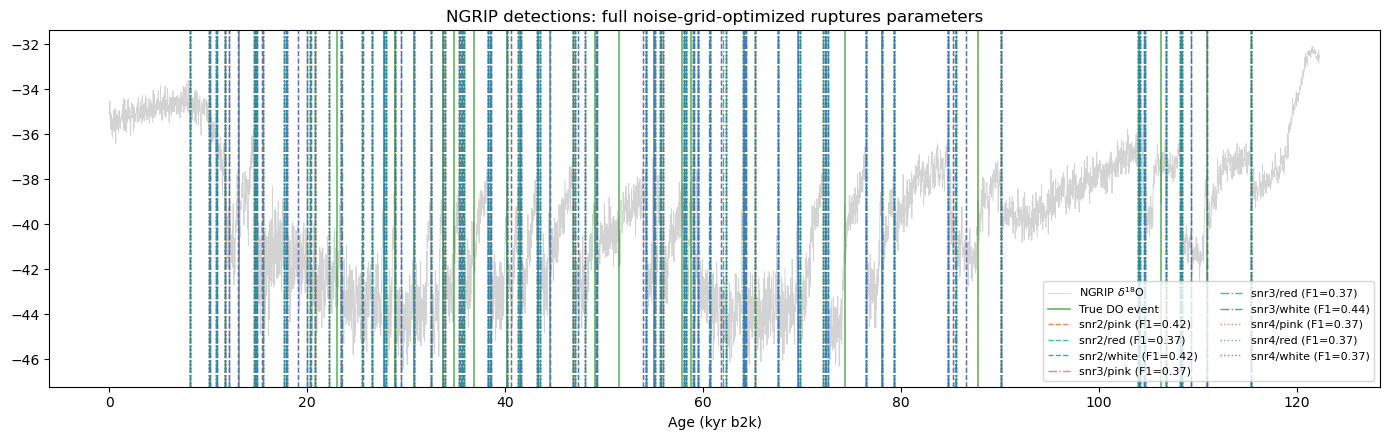

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ngrip.time, ngrip.value, lw=0.6, color='lightgray', label='NGRIP $\\delta^{18}$O')
for i, t in enumerate(main_do_events):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True DO event' if i == 0 else None)

LEVEL_LS = {'snr2': '--', 'snr3': '-.', 'snr4': ':'}
COLOR_MAP = {'white': '#2a78d6', 'pink': '#eb6834', 'red': '#1baf7a'}
for (level, color), res in ngrip_results.items():
    plot_color = COLOR_MAP.get(color, 'gray')
    ls = LEVEL_LS.get(level, '--')
    for i, t in enumerate(res['detected']):
        ax.axvline(t, color=plot_color, ls=ls, lw=1.0, alpha=0.8,
                   label=f"{level}/{color} (F1={res['metrics'].f1_score:.2f})" if i == 0 else None)

ax.set_xlabel('Age (kyr b2k)')
ax.set_title('NGRIP detections: full noise-grid-optimized ruptures parameters')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [12]:
full_summary = pd.DataFrame([
    dict(level=level, color=color,
         params=info['params'],
         synthetic_cv_f1=info['synthetic_cv_f1_mean'],
         ngrip_f1=ngrip_results[(level, color)]['metrics'].f1_score,
         ngrip_precision=ngrip_results[(level, color)]['metrics'].precision,
         ngrip_recall=ngrip_results[(level, color)]['metrics'].recall,
         ngrip_n_detected=ngrip_results[(level, color)]['metrics'].n_detected)
    for (level, color), info in all_conditions.items()
]).sort_values('ngrip_f1', ascending=False).reset_index(drop=True)

print(f"Best NGRIP match overall: '{full_summary.iloc[0]['level']}/{full_summary.iloc[0]['color']}'-optimized parameters "
      f"(NGRIP F1={full_summary.iloc[0]['ngrip_f1']:.3f} vs. synthetic CV F1={full_summary.iloc[0]['synthetic_cv_f1']:.3f})\n")
full_summary

Best NGRIP match overall: 'snr3/white'-optimized parameters (NGRIP F1=0.438 vs. synthetic CV F1=0.829)



,level,color,params,synthetic_cv_f1,ngrip_f1,ngrip_precision,ngrip_recall,ngrip_n_detected
0,snr3,white,"{'algo': 'Pelt', 'cost': 'l1', 'min_size': 10,...",0.829129,0.438356,0.333333,0.64,48
1,snr2,pink,"{'algo': 'Pelt', 'cost': 'l2', 'min_size': 10,...",0.792756,0.417582,0.287879,0.76,66
2,snr2,white,"{'algo': 'Pelt', 'cost': 'l2', 'min_size': 10,...",0.834391,0.417582,0.287879,0.76,66
3,snr2,red,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.814500,0.373626,0.257576,0.68,66
4,snr3,pink,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.815656,0.373626,0.257576,0.68,66
5,snr3,red,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.827551,0.373626,0.257576,0.68,66
6,snr4,pink,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.827222,0.373626,0.257576,0.68,66
7,snr4,red,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.818076,0.373626,0.257576,0.68,66
8,snr4,white,"{'algo': 'BottomUp', 'cost': 'l2', 'min_size':...",0.834545,0.373626,0.257576,0.68,66


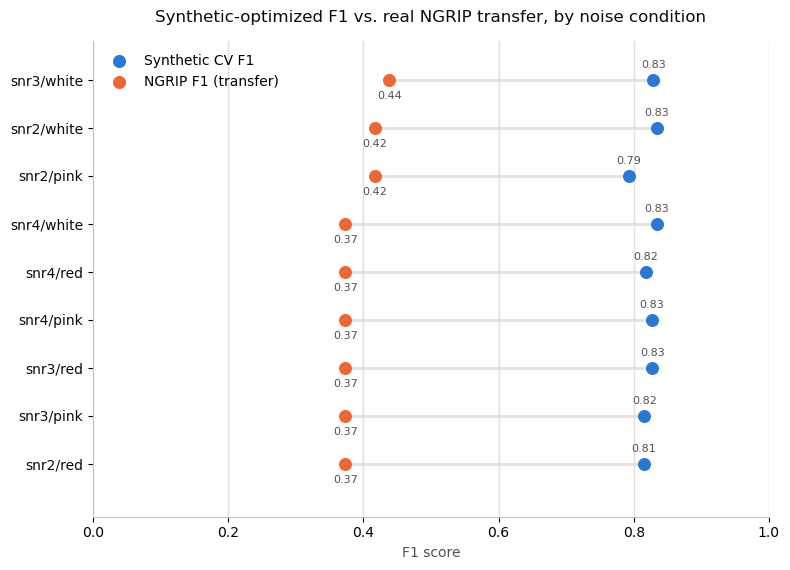

In [13]:
BLUE, ORANGE = '#2a78d6', '#eb6834'
TEXT_PRIMARY, TEXT_SECONDARY = '#0b0b0b', '#52514e'
GRID, SPINE = '#e1e0d9', '#c3c2b7'

plot_df = full_summary.copy()
plot_df['label'] = plot_df['level'] + '/' + plot_df['color']
plot_df = plot_df.sort_values('ngrip_f1', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 5.8))
y = np.arange(len(plot_df))

ax.hlines(y, plot_df['ngrip_f1'], plot_df['synthetic_cv_f1'], color=GRID, linewidth=2, zorder=1)
ax.scatter(plot_df['synthetic_cv_f1'], y, color=BLUE, s=70, zorder=3, label='Synthetic CV F1')
ax.scatter(plot_df['ngrip_f1'], y, color=ORANGE, s=70, zorder=3, label='NGRIP F1 (transfer)')

# ax.axvline(rupt_lit_metrics.f1_score, color=SPINE, linewidth=1.2, linestyle='--', zorder=0)

for yi, (sf1, nf1) in enumerate(zip(plot_df['synthetic_cv_f1'], plot_df['ngrip_f1'])):
    ax.text(sf1, yi + 0.24, f'{sf1:.2f}', color=TEXT_SECONDARY, fontsize=8, ha='center')
    ax.text(nf1, yi - 0.24, f'{nf1:.2f}', color=TEXT_SECONDARY, fontsize=8, va='top', ha='center')

ax.set_yticks(y)
ax.set_yticklabels(plot_df['label'], color=TEXT_PRIMARY)
ax.set_ylim(-1.1, len(plot_df) - 0.2)
ax.set_xlim(0, 1)
ax.set_xlabel('F1 score', color=TEXT_SECONDARY)
ax.set_title('Synthetic-optimized F1 vs. real NGRIP transfer, by noise condition', color=TEXT_PRIMARY, pad=14)
ax.grid(axis='x', color=GRID, linewidth=1, zorder=0)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color(SPINE)

# ax.text(rupt_lit_metrics.f1_score, -1.05, 'literature baseline (Pelt, l2, pen=10)',
#         color=TEXT_SECONDARY, fontsize=8, ha='center', va='bottom')
ax.legend(frameon=False, loc='upper left')

fig.tight_layout()
plt.show()

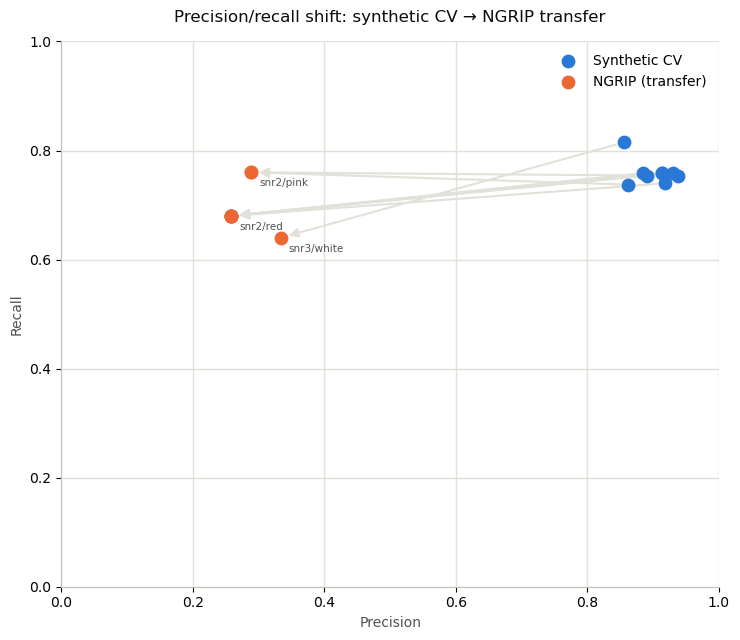

In [14]:
synth_pr = (cv_ruptures.groupby(['level', 'color'])
            .agg(synthetic_precision=('test_precision', 'mean'),
                 synthetic_recall=('test_recall', 'mean'))
            .reset_index())
pr_df = full_summary.merge(synth_pr, on=['level', 'color'])
pr_df['label'] = pr_df['level'] + '/' + pr_df['color']

BLUE, ORANGE = '#2a78d6', '#eb6834'
TEXT_PRIMARY, TEXT_SECONDARY = '#0b0b0b', '#52514e'
GRID, SPINE = '#e1e0d9', '#c3c2b7'

fig, ax = plt.subplots(figsize=(7.5, 6.5))

for _, r in pr_df.iterrows():
    ax.annotate('', xy=(r['ngrip_precision'], r['ngrip_recall']),
                xytext=(r['synthetic_precision'], r['synthetic_recall']),
                arrowprops=dict(arrowstyle='-|>', color=GRID, linewidth=1.5,
                                 shrinkA=6, shrinkB=6, mutation_scale=14), zorder=1)

ax.scatter(pr_df['synthetic_precision'], pr_df['synthetic_recall'], color=BLUE, s=80, zorder=3, label='Synthetic CV')
ax.scatter(pr_df['ngrip_precision'], pr_df['ngrip_recall'], color=ORANGE, s=80, zorder=3, label='NGRIP (transfer)')

# label only distinct NGRIP clusters, since many conditions land on the same point
seen = set()
for _, r in pr_df.iterrows():
    key = (round(r['ngrip_precision'], 3), round(r['ngrip_recall'], 3))
    if key not in seen:
        seen.add(key)
        ax.annotate(r['label'], (r['ngrip_precision'], r['ngrip_recall']),
                    textcoords='offset points', xytext=(6, -10), fontsize=7.5, color=TEXT_SECONDARY)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('Precision', color=TEXT_SECONDARY)
ax.set_ylabel('Recall', color=TEXT_SECONDARY)
ax.set_title('Precision/recall shift: synthetic CV \u2192 NGRIP transfer', color=TEXT_PRIMARY, pad=14)
ax.grid(color=GRID, linewidth=1, zorder=0)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color(SPINE)
ax.legend(frameon=False, loc='upper right')

fig.tight_layout()
plt.show()

**Reading this table:** the `synthetic_cv_f1` column is how well that
color's optimized parameters recovered transitions in *synthetic* data with
that exact noise color; `ngrip_f1` is the same parameters applied unchanged
to the *real* record. A color whose parameters score well on both is the
one whose noise character NGRIP most resembles, by this test. This is only
the SNR2 slice of the grid — snr3/{pink,red} and all of snr4 will extend
this table automatically once their checkpoint entries reach 5/5 folds and
this cell is re-run.